# 23. One-line drawdown trigger: standard AUC and loss trade-off curve

Here I answer two questions on Binance spot BTCUSDT one-minute data, development period 2023-01 to 2026-04.

1. Is in-progress detection trivial? If so, a one-line rule that looks only at the drawdown from the trailing four-hour high should also reach a high standard AUC. I measure its standard AUC, pre-onset AUC and in-progress share with the functions of notebooks 18 and 21 and set them beside M0, GBM and 24-hour volatility.
2. Does selling early in a decline reduce losses, and where are losses smallest? I run the rule "sell when the price is X% below the trailing four-hour high, buy back 240 minutes later" for X = 0.5% to 3% and trace the annual net value (losses avoided on caught crashes minus the cost of false alerts) as a curve.

- The score is `dd_240` = 1 − close / highest close of the trailing 240 minutes (the notebook 16 feature, using the current minute's close). An alert fires at the first minute with `dd_240` ≥ X and starts a 240-minute cooldown, with no annual budget (like a stop-loss). A secondary version uses the notebook 16 calendar budget (20 per month, 240 per year).
- As in notebook 15, I sell at the close of the first minute with volume within 5 minutes after the alert and buy back after 240 minutes; value = −(log return of holding). I charge one-way fees of 0, 5 and 10 bp on both legs.
- As a reference I use the M0 calendar alerts of notebook 05.
- For uncertainty I report the 95% interval of the annual net value from a calendar-month block bootstrap with 2,000 draws.
- I select no optimal X and report the full curve, because an optimum chosen on the development period would be overfit.

I fixed the rules before seeing results and recorded them in `23_SPEC.json`.

This is an exploratory, illustrative calculation that ignores slippage, market impact and taxes, and I do not use the holdouts. I write the results to `btc_lead_cost_results_77months_spot/drawdown_trigger_v1/`.

In [1]:
from pathlib import Path
from collections import deque, defaultdict
import io, os, sys, json, math, time, hashlib, zipfile, warnings, urllib.request, urllib.error
import numpy as np
from numpy.lib.stride_tricks import sliding_window_view
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import binomtest
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
try:
    import pyarrow  # noqa: F401
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'pyarrow'])
try:
    from numba import njit
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'numba'])
    from numba import njit
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not running in Colab: paths below must point to a folder with the same structure.')

DRIVE = Path('/content/drive/MyDrive')
SPOT_BASE = DRIVE / 'btc_lead_cost_results_77months_spot'      # spot results (notebooks 01–07)
FUT_BASE = DRIVE / 'btc_lead_cost_results_77months'            # futures results, read only
BINANCE = 'https://data.binance.vision/data/'
NS = 60 * 10**9
LEAD_MIN = 30; LEAD_MAX = 240; COOLDOWN = 240; COOLDOWN_MIN = 240
B = 240; MONTH_CAP = 20
EVAL_START = '2023-01-01'; EVAL_END = '2026-05-01'

_src = SPOT_BASE / 'cache' / 'DATA_SOURCE.json'
if not _src.is_file() or json.loads(_src.read_text()).get('venue') != 'spot':
    raise RuntimeError(f'Spot cache not found: {_src}. Run notebook 01 first.')
REF_PATH = SPOT_BASE / 'causal_alert_selection_v1' / 'spot_reference.json'
THR_PATH = SPOT_BASE / 'FINAL_risk_adaptive_alert_capacity_v1' / 'spot_frozen_thresholds.json'
for _p in (REF_PATH, THR_PATH):
    if not _p.is_file():
        raise FileNotFoundError(f'Results of notebooks 05 and 06 are required: {_p}')
REF = json.loads(REF_PATH.read_text())
FROZEN = json.loads(THR_PATH.read_text())
assert REF.get('venue') == 'spot' and FROZEN.get('venue') == 'spot'
TH_CAL = float(REF['TH_CAL']); TH_HIGH = float(REF['TH_HIGH']); TH_BUCKET = float(FROZEN['TH_BUCKET'])
print('SPOT cache verified. Frozen spot thresholds:', dict(TH_CAL=TH_CAL, TH_HIGH=TH_HIGH, TH_BUCKET=TH_BUCKET))


def sha256_file(p):
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()
def load_btc_spot():
    px = pd.read_parquet(SPOT_BASE / 'cache' / 'BTCUSDT_1m_regularized.parquet').sort_index()
    sg = pd.read_parquet(SPOT_BASE / 'cache' / 'btc_signals_1m.parquet', columns=['z_vol', 'tsr', 'z_hs']).sort_index()
    for fr in (px, sg):
        assert isinstance(fr.index, pd.DatetimeIndex) and fr.index.tz is not None
        fr.index = fr.index.tz_convert('UTC')
    assert px.index.equals(sg.index), 'price/signal caches must share one 1-minute index'
    assert px.index.is_unique and (np.diff(px.index.asi8) == NS).all()
    return px, sg


def load_catalog(path):
    E = pd.read_csv(path)
    for c in ['peak_utc', 'onset_1pct_utc', 'breach_utc', 'confirmed_utc']:
        E[c] = pd.to_datetime(E[c], utc=True)
    E = E.sort_values('breach_utc').reset_index(drop=True)
    assert E.event_id.is_unique
    return E


def label_from_catalog(T, E):
    """1 if a 4% breach occurs 30-240 minutes after minute t (same rule as notebooks 04–07)."""
    b = E.breach_utc.astype('int64').to_numpy()
    pos = np.searchsorted(b, T + LEAD_MIN * NS, 'left')
    y = np.zeros(len(T), dtype=np.int8)
    ok = pos < len(b)
    y[ok] = (b[pos[ok]] <= T[ok] + LEAD_MAX * NS).astype(np.int8)
    return y


def ts(s):
    return pd.Timestamp(s, tz='UTC')


def in_period(T, start, end):
    return (T >= ts(start).value) & (T < ts(end).value)


def train_mask(T, valid, year=2021):
    return valid & (T >= ts(f'{year}-01-01').value) & (T < ts(f'{year + 1}-01-01').value - (LEAD_MAX + 5) * NS)


def new_logit():
    return make_pipeline(StandardScaler(), LogisticRegression(C=0.2, class_weight='balanced', max_iter=400,
                                                              solver='lbfgs', random_state=17))


def events_between(E, start, end):
    """Evaluation events: breach in [start+4h, end) so every warning window lies inside the period."""
    return E[(E.breach_utc >= ts(start) + pd.Timedelta(minutes=LEAD_MAX)) & (E.breach_utc < ts(end))].reset_index(drop=True)


# --- emit_calendar, as in notebook 05 ---
def emit_calendar(t,eligible,B=240,cap=20,cooldown_min=240):
    t=np.asarray(t,dtype=np.int64)
    eligible=np.asarray(eligible,dtype=bool)
    assert len(t)==len(eligible) and np.all(np.diff(t)>0)
    ids=np.flatnonzero(eligible)
    z=[]; mcount=0; ycount=0; pm=None; py=None; last=-(10**20)
    for k in ids:
        ti=int(t[k]); dt=pd.Timestamp(ti,tz='UTC')
        year=int(dt.year); month=year*12+int(dt.month)
        if year!=py: ycount=0; py=year
        if month!=pm: mcount=0; pm=month
        if ycount>=B or mcount>=cap or ti-last<cooldown_min*NS:continue
        z.append(ti); last=ti; ycount+=1; mcount+=1
    return np.asarray(z,dtype=np.int64)

# --- match_events, as in notebook 05 ---
def match_events(events,alerts):
    alerts=np.sort(np.asarray(alerts,dtype=np.int64))
    out=[];used=set()
    for ev in events.itertuples(index=False):
        breach=ev.breach_utc.value; onset=ev.onset_1pct_utc.value
        left=int(np.searchsorted(alerts,breach-LEAD_MAX*NS,'left'))
        right=int(np.searchsorted(alerts,breach-LEAD_MIN*NS,'right'))
        for j in range(left,right):
            if j not in used:
                used.add(j)
                out.append(dict(event_id=int(ev.event_id),breach_utc=ev.breach_utc,
                                alarm_utc=pd.Timestamp(int(alerts[j]),tz='UTC'),
                                lead_min=(breach-int(alerts[j]))/NS,
                                pre1pct=bool(alerts[j]<onset)))
                break
    return pd.DataFrame(out,columns=['event_id','breach_utc','alarm_utc','lead_min','pre1pct'])

# --- statistics, as in notebook 05 ---
def statistics(events,alerts):
    hits=match_events(events,alerts)
    n=len(alerts);N=len(events)
    return dict(alarms=n,caught=len(hits),before_1pct=int(hits.pre1pct.sum()),
                false_alarms=n-len(hits),recall=len(hits)/N,
                pre_onset_recall=int(hits.pre1pct.sum())/N,
                alert_precision=(len(hits)/n if n else 0))



def cal_fields(t):
    idx = pd.to_datetime(np.asarray(t, dtype='int64'), utc=True)
    years = idx.year.to_numpy().astype(np.int64)
    months = (idx.year.to_numpy() * 12 + idx.month.to_numpy()).astype(np.int64)
    return years, months


@njit(cache=False)
def _calendar_core(t, elig, years, months, B, caps, cooldown_ns):
    # Line-by-line port of emit_calendar with a per-minute monthly cap (caps) so a surge policy can reuse it.
    out = np.empty(len(t), np.int64); k = 0
    mcount = 0; ycount = 0; pm = -1; py = -1; last = -(2**62)
    for i in range(len(t)):
        if not elig[i]:
            continue
        ti = t[i]; yr = years[i]; mo = months[i]
        if yr != py:
            ycount = 0; py = yr
        if mo != pm:
            mcount = 0; pm = mo
        if ycount >= B or mcount >= caps[i] or ti - last < cooldown_ns:
            continue
        out[k] = ti; k += 1; last = ti; ycount += 1; mcount += 1
    return out[:k].copy()


_CAL_CACHE = [None, None]


def emit_calendar_fast(t, eligible, B=240, cap=20, cooldown_min=240, caps=None):
    t = np.asarray(t, dtype=np.int64); eligible = np.asarray(eligible, dtype=bool)
    assert len(t) == len(eligible) and (len(t) < 2 or np.all(np.diff(t) > 0))
    if _CAL_CACHE[0] is t:
        years, months = _CAL_CACHE[1]
    else:
        years, months = cal_fields(t); _CAL_CACHE[0] = t; _CAL_CACHE[1] = (years, months)
    if caps is None:
        caps = np.full(len(t), int(cap), np.int64)
    return _calendar_core(t, eligible, years, months, int(B), np.asarray(caps, np.int64), np.int64(cooldown_min * NS))


def check_fast_calendar(t, s):
    """Stop if the compiled calendar ever differs from the notebook 05 reference implementation."""
    qs = np.unique(np.quantile(s[np.isfinite(s)], [0., .5, .8, .9, .95, .99, .999]))
    for th in qs:
        e = np.isfinite(s) & (s >= th)
        for B_, cap_ in [(240, 20), (60, 5)]:
            if not np.array_equal(emit_calendar(t, e, B=B_, cap=cap_), emit_calendar_fast(t, e, B=B_, cap=cap_)):
                raise AssertionError(f'fast calendar differs from the reference at th={th}, B={B_}')
    return len(qs) * 2


def score_grid(sc):
    Q = np.unique(np.r_[0., np.linspace(.10, .995, 33), .997, .999, .9999, 1.])
    return np.unique(np.r_[np.nextafter(sc.min(), -np.inf), np.quantile(sc, Q), np.nextafter(sc.max(), np.inf)])


def calibrate_calendar(t_cal, s_cal, grid=None, B_=240, cap_=20):
    """Notebook 05 rule: the most 2022 alerts reachable (cap = B), then the fewest raw candidates (strictest)."""
    grid = score_grid(s_cal) if grid is None else grid
    rows = []
    for th in grid:
        e = s_cal >= th
        rows.append((float(th), len(emit_calendar_fast(t_cal, e, B=B_, cap=cap_)), int(e.sum())))
    df = pd.DataFrame(rows, columns=['threshold', 'cal_alerts', 'raw_candidates'])
    best = df[df.cal_alerts == df.cal_alerts.max()].sort_values('raw_candidates').iloc[0]
    return float(best.threshold), int(best.cal_alerts), df


def mcnemar_one_sided(a_only, b_only):
    """P(at least b_only successes | n discordant, p=.5): evidence that B beats A."""
    n = a_only + b_only
    return float(binomtest(b_only, n, .5, alternative='greater').pvalue) if n else 1.0


def mcnemar_two_sided(a_only, b_only):
    n = a_only + b_only
    return float(binomtest(min(a_only, b_only), n, .5).pvalue) if n else 1.0


def paired(events, base_alerts, new_alerts):
    mb = match_events(events, base_alerts); mn = match_events(events, new_alerts)
    hb, hn = set(mb.event_id), set(mn.event_id)
    pb, pn = set(mb.loc[mb.pre1pct, 'event_id']), set(mn.loc[mn.pre1pct, 'event_id'])
    return dict(base_caught=len(hb), new_caught=len(hn), base_only_caught=len(hb - hn), new_only_caught=len(hn - hb),
                p_caught_two_sided=mcnemar_two_sided(len(hb - hn), len(hn - hb)),
                base_pre1pct=len(pb), new_pre1pct=len(pn), base_only_pre1pct=len(pb - pn), new_only_pre1pct=len(pn - pb),
                p_pre1pct_two_sided=mcnemar_two_sided(len(pb - pn), len(pn - pb)),
                p_pre1pct_one_sided_new_better=mcnemar_one_sided(len(pb - pn), len(pn - pb)))
RAW_COLS = ['open_time', 'open', 'high', 'low', 'close', 'volume', 'close_time', 'quote_volume',
            'trade_count', 'taker_buy_vol', 'taker_buy_quote', 'ignore']


def month_list(first, last):
    return [p.strftime('%Y-%m') for p in pd.period_range(first, last, freq='M')]


def _fetch(url, tries=5):
    last = None
    for k in range(tries):
        try:
            req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
            with urllib.request.urlopen(req, timeout=120) as r:
                return r.read()
        except urllib.error.HTTPError as e:
            if e.code == 404:
                return None
            last = e
        except Exception as e:  # network hiccup: retry
            last = e
        time.sleep(2 ** k)
    raise RuntimeError(f'download failed: {url} ({last})')


def get_archives(prefix, symbol, months, dest, allow_missing=False):
    """Binance public monthly 1m klines (prefix 'spot' or 'futures/um'), SHA-256 checked against .CHECKSUM.
    Already-downloaded files whose hash matches are reused, so an interrupted run resumes."""
    dest = Path(dest); dest.mkdir(parents=True, exist_ok=True)
    rows = []
    for ym in months:
        url = f'{BINANCE}{prefix}/monthly/klines/{symbol}/1m/{symbol}-1m-{ym}.zip'
        z = dest / f'{symbol}-1m-{ym}.zip'
        chk = _fetch(url + '.CHECKSUM')
        if chk is None:
            if allow_missing:
                rows.append(dict(symbol=symbol, venue=prefix, month=ym, url=url, sha256=None, status='not_listed'))
                continue
            raise RuntimeError(f'archive not published: {url}')
        expected = chk.decode().split()[0].strip().lower()
        if z.is_file() and sha256_file(z) == expected:
            status = 'cached'
        else:
            data = _fetch(url)
            if data is None:
                raise RuntimeError(f'archive missing although checksum exists: {url}')
            if hashlib.sha256(data).hexdigest() != expected:
                raise RuntimeError(f'SHA-256 mismatch: {url}')
            part = z.parent / (z.name + '.part'); part.write_bytes(data); part.replace(z)
            status = 'downloaded'
        rows.append(dict(symbol=symbol, venue=prefix, month=ym, url=url, sha256=expected, status=status))
    man = pd.DataFrame(rows)
    print(symbol, prefix, man.status.value_counts().to_dict(), flush=True)
    return man


def parse_kline_zip(path):
    """Header or no header; ms or microsecond timestamps (spot archives switched to microseconds in 2025)."""
    with zipfile.ZipFile(path) as zf:
        members = [m for m in zf.namelist() if m.lower().endswith('.csv')]
        if len(members) != 1:
            raise ValueError(f'expected one CSV in {path}')
        with zf.open(members[0]) as fd:
            x = pd.read_csv(fd, header=None, low_memory=False)
    if str(x.iloc[0, 0]).strip().lower() in ('open_time', 'timestamp'):
        x = x.iloc[1:].reset_index(drop=True)
    if x.shape[1] < 12:
        raise ValueError(f'unexpected kline schema in {path}: {x.shape[1]} columns')
    x = x.iloc[:, :12]; x.columns = RAW_COLS
    number = pd.to_numeric(x.open_time, errors='raise')
    mag = float(number.abs().median())
    unit = 'us' if mag > 1e14 else ('ms' if mag > 1e11 else 's')
    z = x[['open', 'high', 'low', 'close', 'volume', 'taker_buy_vol']].apply(pd.to_numeric, errors='coerce')
    z.index = pd.DatetimeIndex(pd.to_datetime(number, unit=unit, utc=True), name='open_time')
    return z[~z.index.duplicated(keep='last')].sort_index().astype('float64')


def load_archives(manifest, folder):
    parts = [parse_kline_zip(Path(folder) / f"{r.symbol}-1m-{r.month}.zip") for r in manifest.itertuples() if r.status != 'not_listed']
    raw = pd.concat(parts).sort_index(kind='stable')
    return raw[~raw.index.duplicated(keep='last')]


def regularize(raw, start=None, end=None):
    """Notebook 01 gap policy: complete UTC minute grid; missing runs of <=5 minutes get forward-filled OHLC and
    zero volume; longer gaps stay NaN."""
    full = pd.date_range(raw.index.min() if start is None else start, raw.index.max() if end is None else end,
                         freq='min', tz='UTC')
    out = raw.reindex(full); out.index.name = 'open_time'
    missing = ~full.isin(raw.index)
    if missing.any():
        changes = np.r_[True, missing[1:] != missing[:-1]]
        grp = np.cumsum(changes) - 1
        runs = np.bincount(grp[missing], minlength=int(grp.max()) + 1)
        short = missing & (runs[grp] <= 5)
        for c in ['open', 'high', 'low', 'close']:
            out.loc[short, c] = out[c].ffill().loc[short]
        for c in ['volume', 'taker_buy_vol']:
            out.loc[short, c] = 0.0
    return out.astype('float64')


# --- chunked_hs, as in notebook 01 ---
def chunked_hs(close,M=32,K=8,chunk=100_000):
    p=close.to_numpy(dtype=np.float32)
    result=np.full(len(p),np.nan,dtype=np.float64)
    for start in range(M-1,len(p),chunk):
        end=min(len(p),start+chunk)
        w=sliding_window_view(p[start-M+1:end],M)
        zero_mean=w-w.mean(axis=1,keepdims=True)
        result[start:end]=np.abs(np.fft.rfft(zero_mean,axis=1))[:,-K:].mean(axis=1)
        if start==(M-1) or end==len(p): print(f'FFT computation {end:,}/{len(p):,}',flush=True)
    return pd.Series(result,index=close.index)



def compute_spot_features(px, with_hs=True):
    """Exactly the notebook 01 signal formulas (z_hs, z_vol, tsr), float32 like the cache."""
    close = px['close']
    r = np.log(close).diff()
    M = 32; rolling_min = 30 * 1440
    out = {}
    if with_hs:
        hs = chunked_hs(close, M=32, K=8)
        log_hs = np.log1p(hs)
        hs_roll = log_hs.rolling(rolling_min, min_periods=rolling_min // 2)
        out['z_hs'] = ((log_hs - hs_roll.mean().shift(1)) / hs_roll.std().shift(1).replace(0, np.nan)).astype('float32')
    rv = r.rolling(M - 1, min_periods=M - 1).std()
    lrv = np.log(rv.where(rv > 0))
    rv_base = lrv.rolling(rolling_min, min_periods=rolling_min // 2)
    out['z_vol'] = ((lrv - rv_base.mean().shift(1)) / rv_base.std().shift(1).replace(0, np.nan)).astype('float32')
    out['tsr'] = ((px.volume - px.taker_buy_vol) / px.volume.replace(0, np.nan)).clip(0, 1).astype('float32')
    return pd.DataFrame(out, index=px.index)


# --- price_only_catalog, as in notebook 07 ---
def price_only_catalog(close,volume,index,H=240,decline=.04,sustain=5,refractory=1440):
    c=np.asarray(close,dtype=np.float64)
    obs=np.isfinite(c)&(c>0)&np.isfinite(volume)&(np.asarray(volume)>0)
    prior=pd.Series(np.where(obs,c,np.nan)).rolling(H,min_periods=H).max().shift(1).to_numpy()
    raw=obs & np.isfinite(prior) & (c<=(1-decline)*prior)
    fresh=raw & ~np.r_[False,raw[:-1]]
    rows=[];last_confirm=-10**12
    for i in np.flatnonzero(fresh):
        if i+sustain>len(c) or i-last_confirm<refractory:continue
        threshold=(1-decline)*prior[i]
        if not(obs[i:i+sustain].all() and np.all(c[i:i+sustain]<=threshold)):continue
        if i-H<0 or not obs[i-H:i].all():continue
        prev=c[i-H:i];peak_i=int(i-H+np.argmax(prev))
        if peak_i<=last_confirm:continue
        onset_candidates=np.flatnonzero(c[peak_i+1:i+1]<=.99*c[peak_i])
        if not len(onset_candidates):continue
        oi=int(peak_i+1+onset_candidates[0])
        rows.append({'event_id':len(rows)+1,'peak_utc':index[peak_i],
                     'onset_1pct_utc':index[oi], 'breach_utc':index[i],
                     'confirmed_utc':index[i+sustain-1],
                     'peak_close':float(c[peak_i]),'breach_close':float(c[i]),
                     'decline_at_breach_pct':(c[i]/c[peak_i]-1)*100,
                     'peak_to_breach_minutes':i-peak_i,
                     'onset_to_breach_minutes':i-oi})
        last_confirm=i+sustain-1
    df=pd.DataFrame(rows)
    if not len(df):raise RuntimeError('No price-only crash events generated; inspect price history')
    df['year']=pd.DatetimeIndex(df.breach_utc).year
    return df

# Shared by notebooks 18 and 19: exact block-bootstrap AUC decomposition.
def week_pairs(sp, wp, sn, wn):
    """C[k, l] = over positives in block k, the number of negatives in block l with a lower score (+0.5 per tie).
    With block multiplicities w from the bootstrap, the AUC is w'Cw / ((w'P)(w'N)); w = 1 gives the ordinary AUC."""
    C = np.zeros((N_WEEKS, N_WEEKS))
    if len(sp) == 0 or len(sn) == 0:
        return C
    o = np.lexsort((sn, wn)); sn = sn[o]; wn = wn[o]
    bounds = np.searchsorted(wn, np.arange(N_WEEKS + 1), 'left')
    for l in range(N_WEEKS):
        a, b = bounds[l], bounds[l + 1]
        if a == b:
            continue
        seg = sn[a:b]; lo = np.searchsorted(seg, sp, 'left'); hi = np.searchsorted(seg, sp, 'right')
        C[:, l] = np.bincount(wp, weights=lo + 0.5 * (hi - lo), minlength=N_WEEKS)
    return C


def _ratio(a, b):
    return a / b if b > 0 else np.nan


STAT_KEYS = ['auc_standard', 'auc_pre', 'auc_in', 'share_in', 'diff_standard_minus_pre', 'in_share_of_excess', 'auc_calm',
             'auc_standard_within_regime', 'auc_pre_within_regime', 'auc_in_within_regime']


def make_parts(sm, code, calm, wk, dec):
    neg = code == 0; pre = code == 1; inn = code == 2; cnt = lambda k: np.bincount(wk[k], minlength=N_WEEKS).astype(float)
    P = dict(C_pre=week_pairs(sm[pre], wk[pre], sm[neg], wk[neg]), C_in=week_pairs(sm[inn], wk[inn], sm[neg], wk[neg]),
             C_calm=week_pairs(sm[(code > 0) & calm], wk[(code > 0) & calm], sm[neg & calm], wk[neg & calm]),
             P_pre=cnt(pre), P_in=cnt(inn), N=cnt(neg), P_calm=cnt((code > 0) & calm), N_calm=cnt(neg & calm),
             Cs_pre=np.zeros((N_WEEKS, N_WEEKS)), Cs_in=np.zeros((N_WEEKS, N_WEEKS)), Pq_pre=[], Pq_in=[], Nq=[])
    for q in range(10):
        kq = dec == q; nq = neg & kq; pq = pre & kq; iq = inn & kq
        P['Cs_pre'] += week_pairs(sm[pq], wk[pq], sm[nq], wk[nq]); P['Cs_in'] += week_pairs(sm[iq], wk[iq], sm[nq], wk[nq])
        P['Pq_pre'].append(cnt(pq)); P['Pq_in'].append(cnt(iq)); P['Nq'].append(cnt(nq))
    for k in ('Pq_pre', 'Pq_in', 'Nq'):
        P[k] = np.array(P[k])
    return P


def stats_from(P, w):
    q = lambda C: w @ C @ w
    Wn = w @ P['N']; Wp = w @ P['P_pre']; Wi = w @ P['P_in']; sp = q(P['C_pre']); si = q(P['C_in'])
    std = _ratio(sp + si, (Wp + Wi) * Wn); pre = _ratio(sp, Wp * Wn); inn = _ratio(si, Wi * Wn); pi = _ratio(Wi, Wp + Wi)
    nq = P['Nq'] @ w; pq = P['Pq_pre'] @ w; iq = P['Pq_in'] @ w; ssp = q(P['Cs_pre']); ssi = q(P['Cs_in'])
    return dict(auc_standard=std, auc_pre=pre, auc_in=inn, share_in=pi, diff_standard_minus_pre=std - pre,
                in_share_of_excess=_ratio(pi * (inn - 0.5), std - 0.5) if np.isfinite(inn) else 0.0,
                auc_calm=_ratio(q(P['C_calm']), (w @ P['P_calm']) * (w @ P['N_calm'])),
                auc_standard_within_regime=_ratio(ssp + ssi, ((pq + iq) * nq).sum()),
                auc_pre_within_regime=_ratio(ssp, (pq * nq).sum()), auc_in_within_regime=_ratio(ssi, (iq * nq).sum()))

OUT = SPOT_BASE / 'drawdown_trigger_v1'; OUT.mkdir(parents=True, exist_ok=True)
CAS = SPOT_BASE / 'causal_alert_selection_v1'; VAL15 = SPOT_BASE / 'detection_value_v1'; M21 = SPOT_BASE / 'onset_positioning_volatility_v1'
X_GRID = [0.5, 0.75, 1.0, 1.25, 1.5, 2.0, 2.5, 3.0]          # percent below the trailing 240-min high
HOLD = 240; FEES_BP = [0, 5, 10]; MAX_WAIT = 5; RV_WINDOW = 1440; DCL = 0.04
N_BOOT = 500; N_BOOT_M = 2000; SEED = 20261106; BLOCK_DAYS = 7
EVAL_LAST = ts(EVAL_END).value - (LEAD_MAX + 5) * NS
for _p in [CAS / 'alarms_first_eligible.csv', VAL15 / '2_net_value_by_fee.csv', M21 / '1_onset_per_minute.csv']:
    if not _p.is_file():
        raise FileNotFoundError(f'Results of notebooks 05, 15 and 21 are required: {_p}')

SPEC = {'title': 'One-line drawdown trigger: standard AUC and loss trade-off curve (dev 2023-01..2026-04, exploratory)',
        'score': 'dd_240 = 1 - close / max close over the trailing 240 minutes (min 120), as notebook-16 feature dd_240',
        'rule': {'X_percent': X_GRID, 'alert': 'first minute with dd_240 >= X, then a 240-min cooldown; no annual budget (primary)',
                 'secondary': 'same eligibility through the notebook-16 calendar scheduler (20/month, 240/year)'},
        'per_minute': 'notebook-18/21 decomposition of dd_240 (labels: 4% catalog, 30-240 min; in-decline split at the 1% onset), '
                      f'{N_BOOT} x {BLOCK_DAYS}-day block bootstrap',
        'value': f'notebook-15 action: exit at the first positive-volume close within {MAX_WAIT} min after the alert minute, re-enter after {HOLD} min; '
                 'value = -log return over the hold; one-way fees ' + str(FEES_BP) + ' bp charged on both legs; annual value = simple sum / years',
        'event_level': 'matched events (notebook-4 matching): drawdown from the event peak at entry, decline avoided to the breach close, '
                       'share of the peak-to-24h-trough fall avoided (hindsight upper bound)',
        'uncertainty': f'calendar-month block bootstrap, {N_BOOT_M} draws, 95% interval of the annual net value',
        'reference': 'M0 calendar alarms (notebook 5), valued identically; must reproduce notebook 15',
        'selection': 'no trigger is selected or recommended; the full curve is reported', 'seed': SEED, 'holdouts': 'not used'}
_raw = (json.dumps(SPEC, indent=2, sort_keys=True, default=str) + '\n').encode()
_sp = OUT / '23_SPEC.json'
if _sp.exists() and _sp.read_bytes() != _raw:
    _sp.rename(OUT / f'23_SPEC.replaced_{pd.Timestamp.now(tz="UTC"):%Y%m%dT%H%M%S}.json')
_sp.write_bytes(_raw); SPEC_SHA = hashlib.sha256(_raw).hexdigest()
print('Output:', OUT, '| spec sha256', SPEC_SHA[:16])

Mounted at /content/drive
SPOT cache verified. Frozen spot thresholds: {'TH_CAL': 0.6698990591069133, 'TH_HIGH': 0.6864782740093911, 'TH_BUCKET': 0.7166067355142407}
Output: /content/drive/MyDrive/btc_lead_cost_results_77months_spot/drawdown_trigger_v1 | spec sha256 aa97489143ba8687


## 1. Data, events and reference alerts (reproduction check)

In [2]:
t_ = time.time()
px, sg = load_btc_spot()
T = px.index.asi8; close = px.close.to_numpy(float); volume = px.volume.to_numpy(float)
v_ = sg.z_vol.to_numpy(float); f_ = sg.tsr.to_numpy(float); h_ = sg.z_hs.to_numpy(float)
VALID = (np.isfinite(close) & (close > 0) & np.isfinite(volume) & (volume > 0) & np.isfinite(v_) & np.isfinite(f_) & np.isfinite(h_) & (f_ >= 0) & (f_ <= 1))
EVM = VALID & (T >= ts(EVAL_START).value) & (T < EVAL_LAST)
_cs = pd.Series(close)
DD = (1 - _cs / _cs.rolling(240, min_periods=120).max()).to_numpy()
CALM = np.isfinite(DD) & (DD < DCL / 4)
_lc = np.log(np.where(np.isfinite(close) & (close > 0), close, np.nan))
RV = pd.Series(_lc).diff().rolling(RV_WINDOW, min_periods=RV_WINDOW // 2).std().to_numpy()
DEC = np.full(len(T), -1, np.int64); _okr = EVM & np.isfinite(RV)
DEC[_okr] = np.minimum((pd.Series(RV[_okr]).rank(pct=True).to_numpy() * 10).astype(int), 9)
WEEK = np.where(EVM, (T - ts(EVAL_START).value) // (BLOCK_DAYS * 1440 * NS), -1).astype(np.int64)
N_WEEKS = int(WEEK[EVM].max()) + 1

E = load_catalog(SPOT_BASE / 'event_definition_eligibility_audit' / 'price_only_event_catalog.csv')
EV = events_between(E, EVAL_START, EVAL_END)
A0 = np.sort(pd.to_datetime(pd.read_csv(CAS / 'alarms_first_eligible.csv').alarm_utc, utc=True).astype('int64').to_numpy())
st0 = statistics(EV, A0)
if [st0['alarms'], st0['caught'], st0['before_1pct']] != REF['first_eligible']:
    raise RuntimeError('GUARD FAIL: M0 calendar alarms do not reproduce notebook 5')

good = np.isfinite(close) & (close > 0) & np.isfinite(volume) & (volume > 0)
_idx = np.where(good, np.arange(len(T)), len(T)); NEXT_GOOD = np.minimum.accumulate(_idx[::-1])[::-1]
CF = pd.Series(close).ffill().to_numpy()


def entry_idx(times):
    i0 = np.minimum(np.searchsorted(T, np.asarray(times, np.int64), 'right'), len(T) - 1); ie = NEXT_GOOD[i0]
    return np.where((ie < len(T)) & (ie - i0 < MAX_WAIT), ie, -1)


def fwd_avoided(ie, H=HOLD):
    ok = (ie >= 0) & (ie + H < len(T)); out = np.full(len(ie), np.nan)
    out[ok] = -np.log(CF[ie[ok] + H] / CF[ie[ok]])
    return out


YEARS = (ts(EVAL_END).value - ts(EVAL_START).value) / (365.25 * 1440 * NS)
v15 = pd.read_csv(VAL15 / '2_net_value_by_fee.csv')
r15 = v15[(v15.policy == 'calendar') & (v15.period == 'dev') & (v15.subset == 'all alerts') & (v15.one_way_fee_bp == 0)].iloc[0]
_x0 = fwd_avoided(entry_idx(A0)); _x0 = _x0[np.isfinite(_x0)]
if len(_x0) != int(r15.alerts) or abs(1e4 * _x0.mean() - float(r15.mean_net_per_alert_bp)) > 1e-6:
    raise RuntimeError('GUARD FAIL: M0 alert values differ from notebook 15')
print(f'{len(EV)} dev events; M0 calendar alarms and their values reproduce notebooks 5 and 15 ({time.time() - t_:.0f}s)')

83 dev events; M0 calendar alarms and their values reproduce notebooks 5 and 15 (14s)


## 2. Per-minute AUC of the one-line rule (standard vs pre-onset vs within-regime)

In [3]:
def eval_case(s, y, inn, base, seed, guard=False):
    m = base & np.isfinite(s) & (DEC >= 0)
    code = np.where(y[m] == 1, np.where(inn[m], 2, 1), 0).astype(np.int64)
    P = make_parts(s[m], code, CALM[m], WEEK[m], DEC[m])
    point = stats_from(P, np.ones(N_WEEKS))
    point.update(n_pre=int((code == 1).sum()), n_in=int((code == 2).sum()), n_neg=int((code == 0).sum()))
    if guard:
        from sklearn.metrics import roc_auc_score
        keep = code != 2
        if abs(roc_auc_score((code[keep] > 0).astype(int), s[m][keep]) - point['auc_pre']) > 1e-9:
            raise RuntimeError('GUARD FAIL: block-pair AUC differs from sklearn')
        print('PASS: block-pair AUC equals sklearn')
    rng = np.random.default_rng(seed); boot = {k: np.empty(N_BOOT) for k in STAT_KEYS}
    for i in range(N_BOOT):
        r = stats_from(P, np.bincount(rng.integers(0, N_WEEKS, N_WEEKS), minlength=N_WEEKS).astype(float))
        for k in STAT_KEYS:
            boot[k][i] = r[k]
    for k in STAT_KEYS:
        lo, hi = np.nanpercentile(boot[k], [2.5, 97.5]) if np.isfinite(boot[k]).any() else (np.nan, np.nan)
        point[f'{k}_lo'] = float(lo); point[f'{k}_hi'] = float(hi)
    return point


y_l1 = label_from_catalog(T, E)
_br = E.breach_utc.astype('int64').to_numpy(); _on = E.onset_1pct_utc.astype('int64').to_numpy()
_pos = np.searchsorted(_br, T + LEAD_MIN * NS, 'left'); _ok = _pos < len(_br)
INN = np.zeros(len(T), bool); INN[_ok] = T[_ok] >= _on[_pos[_ok]]; INN &= (y_l1 == 1)
r_dd = eval_case(np.where(VALID, DD, np.nan), y_l1, INN, EVM, SEED, guard=True)
R21 = pd.read_csv(M21 / '1_onset_per_minute.csv'); R21 = R21[R21.onset == '1pct']
KEEP = ['auc_standard', 'auc_pre', 'auc_in', 'in_share_of_excess', 'in_share_of_excess_lo', 'in_share_of_excess_hi',
        'auc_pre_within_regime', 'auc_pre_within_regime_lo', 'auc_pre_within_regime_hi']
AUCT = pd.concat([pd.DataFrame([dict(score='DD_one_line_rule', **{k: r_dd[k] for k in KEEP})]),
                  R21[R21.score.isin(['M0_VF_logit', 'M3_GBM_rich', 'M1_vol_threshold', 'B0_RV24h_baseline'])][['score'] + KEEP]], ignore_index=True)
AUCT.to_csv(OUT / '1_one_line_rule_auc.csv', index=False); display(AUCT.round(3))

PASS: block-pair AUC equals sklearn


,score,auc_standard,auc_pre,auc_in,in_share_of_excess,in_share_of_excess_lo,in_share_of_excess_hi,auc_pre_within_regime,auc_pre_within_regime_lo,auc_pre_within_regime_hi
0,DD_one_line_rule,0.688,0.517,0.931,0.947,0.827,1.101,0.442,0.397,0.504
1,M0_VF_logit,0.763,0.673,0.891,0.615,0.537,0.694,0.592,0.548,0.642
2,M1_vol_threshold,0.764,0.674,0.891,0.613,0.527,0.697,0.594,0.548,0.637
3,M3_GBM_rich,0.755,0.654,0.899,0.646,0.555,0.727,0.547,0.502,0.602
4,B0_RV24h_baseline,0.748,0.709,0.802,0.505,0.412,0.599,0.511,0.451,0.568


## 3. Trade-off by trigger depth X

- `hit`: an alert that the notebook 04 matching assigns to an event (30–240 minutes before the breach, first alert per event).
- `drawdown_at_entry`: how far the price had already fallen from the event peak at the sale, for caught events; `share_avoided`: the share of the peak-to-24-hour-trough fall that the sale avoids (hindsight upper bound).
- `break_even_fee_bp`: value per alert before fees divided by 2; a one-way fee above this makes the rule lose money.

In [4]:
INWIN = (T >= ts(EVAL_START).value) & (T < ts(EVAL_END).value) & good & np.isfinite(DD)
MONTH = pd.to_datetime(T, utc=True).year.to_numpy() * 12 + pd.to_datetime(T, utc=True).month.to_numpy()
UM = np.unique(MONTH[INWIN])


def evaluate(label, policy, a):
    a = np.sort(np.asarray(a, np.int64)); ie = entry_idx(a); val = fwd_avoided(ie); okv = np.isfinite(val)
    m = match_events(EV, a); hit = np.isin(a, m.alarm_utc.astype('int64').to_numpy()) if len(m) else np.zeros(len(a), bool)
    mm = m.merge(EV[['event_id', 'peak_close']], on='event_id') if len(m) else m
    dd_e, sh = [], []
    for r in mm.itertuples():
        j = int(np.searchsorted(a, r.alarm_utc.value)); e_ = ie[j]
        if e_ < 0:
            continue
        ib = int(np.searchsorted(T, r.breach_utc.value)); tr24 = np.nanmin(close[ib:ib + 1441]); pe = CF[e_]
        dd_e.append(100 * (1 - pe / r.peak_close)); sh.append((pe - tr24) / (r.peak_close - tr24) if r.peak_close > tr24 else np.nan)
    am = MONTH[np.clip(np.searchsorted(T, a, 'left'), 0, len(T) - 1)]
    row = dict(rule=label, policy=policy, alerts=int(okv.sum()), alerts_per_year=float(okv.sum() / YEARS), events=len(EV),
               caught=len(m), pre_onset=int(m.pre1pct.sum()) if len(m) else 0, hit_share_of_alerts=float(hit[okv].mean()) if okv.any() else np.nan,
               median_drawdown_at_entry_pct=float(np.median(dd_e)) if dd_e else np.nan, median_share_avoided=float(np.nanmedian(sh)) if sh else np.nan,
               value_per_alert_bp=1e4 * float(val[okv].mean()) if okv.any() else np.nan,
               value_per_hit_bp=1e4 * float(val[okv & hit].mean()) if (okv & hit).any() else np.nan,
               value_per_nonhit_bp=1e4 * float(val[okv & ~hit].mean()) if (okv & ~hit).any() else np.nan)
    row['break_even_fee_bp'] = row['value_per_alert_bp'] / 2
    msum = {f: np.array([float((val[okv & (am == u)] - 2 * f * 1e-4).sum()) for u in UM]) for f in FEES_BP}
    rng = np.random.default_rng(SEED + 7)
    picks = rng.integers(0, len(UM), (N_BOOT_M, len(UM)))
    for f in FEES_BP:
        row[f'net_pct_per_year_fee{f}'] = 100 * float(msum[f].sum()) / YEARS
        b = 100 * msum[f][picks].sum(axis=1) / YEARS
        row[f'net_pct_per_year_fee{f}_lo'], row[f'net_pct_per_year_fee{f}_hi'] = (float(x) for x in np.percentile(b, [2.5, 97.5]))
    return row


rows = [evaluate('M0 (reference)', 'calendar 240/yr', A0)]
_bud = None
for X in X_GRID:
    elig = INWIN & (DD >= X / 100)
    rows.append(evaluate(f'DD >= {X}%', 'cooldown only', emit_calendar_fast(T, elig, B=10**9, cap=10**9, cooldown_min=COOLDOWN)))
    rows.append(evaluate(f'DD >= {X}%', 'calendar 240/yr', emit_calendar_fast(T, elig, B=B, cap=MONTH_CAP, cooldown_min=COOLDOWN)))
TR = pd.DataFrame(rows)
if abs(TR.iloc[0].value_per_alert_bp - float(r15.mean_net_per_alert_bp)) > 1e-6:
    raise RuntimeError('GUARD FAIL: M0 reference row differs from notebook 15')
TR.to_csv(OUT / '2_trigger_tradeoff.csv', index=False)
cols = ['rule', 'policy', 'alerts_per_year', 'caught', 'pre_onset', 'hit_share_of_alerts', 'median_drawdown_at_entry_pct', 'median_share_avoided',
        'value_per_hit_bp', 'value_per_nonhit_bp', 'break_even_fee_bp', 'net_pct_per_year_fee0', 'net_pct_per_year_fee5', 'net_pct_per_year_fee10']
display(TR[cols].round(3))

,rule,policy,alerts_per_year,caught,pre_onset,hit_share_of_alerts,median_drawdown_at_entry_pct,median_share_avoided,value_per_hit_bp,value_per_nonhit_bp,break_even_fee_bp,net_pct_per_year_fee0,net_pct_per_year_fee5,net_pct_per_year_fee10
0,M0 (reference),calendar 240/yr,240.296,39,22,0.049,1.181,0.847,306.538,-9.810,2.806,13.486,-10.544,-34.573
1,DD >= 0.5%,cooldown only,1594.965,70,38,0.013,1.365,0.808,273.877,-6.509,-1.406,-44.864,-204.361,-363.857
2,DD >= 0.5%,calendar 240/yr,240.296,12,8,0.015,1.050,0.883,342.883,-8.235,-1.484,-7.133,-31.162,-55.192
3,DD >= 0.75%,cooldown only,1162.733,76,50,0.020,0.996,0.843,316.421,-8.795,-1.205,-28.027,-144.301,-260.574
4,DD >= 0.75%,calendar 240/yr,240.296,17,9,0.021,1.144,0.845,315.703,-7.586,-0.358,-1.722,-25.751,-49.781
5,DD >= 1.0%,cooldown only,829.622,72,23,0.026,1.156,0.821,302.667,-11.211,-1.515,-25.131,-108.093,-191.055
6,DD >= 1.0%,calendar 240/yr,240.296,24,12,0.030,1.233,0.831,351.881,-8.341,1.233,5.925,-18.104,-42.134
7,DD >= 1.25%,cooldown only,601.942,71,13,0.035,1.346,0.787,302.088,-14.400,-1.594,-19.185,-79.379,-139.573
8,DD >= 1.25%,calendar 240/yr,237.893,27,6,0.034,1.330,0.821,320.593,-9.317,0.965,4.591,-19.199,-42.988
9,DD >= 1.5%,cooldown only,449.354,68,7,0.045,1.557,0.753,285.694,-17.563,-1.889,-16.980,-61.915,-106.851


## 4. Figures and summary

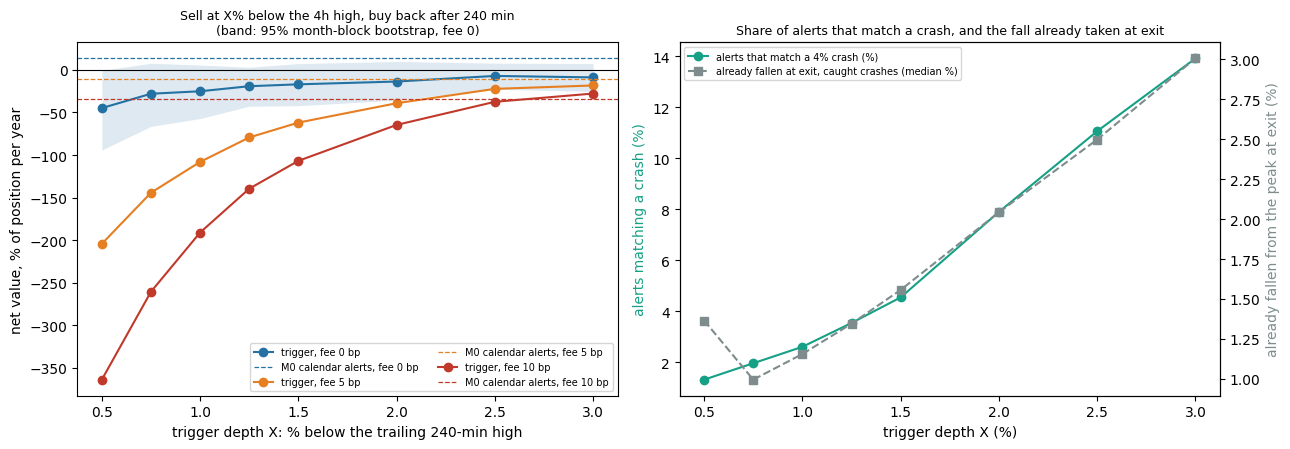

One-line rule (dd_240): standard AUC 0.688, pre-onset 0.517, within-regime pre-onset 0.442, in-decline share 0.95
  vs M0_VF_logit: standard AUC 0.763, pre-onset 0.673, within-regime pre-onset 0.592
  vs M3_GBM_rich: standard AUC 0.755, pre-onset 0.654, within-regime pre-onset 0.547
  vs B0_RV24h_baseline: standard AUC 0.748, pre-onset 0.709, within-regime pre-onset 0.511
M0 (reference)  calendar 240/yr  alerts/yr    240 | caught  39 (pre 22) | hit share   4.9% | fallen at exit 1.18% | per alert   +5.6 bp (break-even fee  +2.8 bp) | %/yr fee0  +13.5 [-8.0, +34.6], fee5  -10.5, fee10  -34.6
DD >= 0.5%      cooldown only    alerts/yr   1595 | caught  70 (pre 38) | hit share   1.3% | fallen at exit 1.37% | per alert   -2.8 bp (break-even fee  -1.4 bp) | %/yr fee0  -44.9 [-94.2, -0.7], fee5 -204.4, fee10 -363.9
DD >= 0.5%      calendar 240/yr  alerts/yr    240 | caught  12 (pre  8) | hit share   1.5% | fallen at exit 1.05% | per alert   -3.0 bp (break-even fee  -1.5 bp) | %/yr fee0   -7.1 

In [5]:
co = TR[TR.policy == 'cooldown only'].reset_index(drop=True); ref0 = TR.iloc[0]; x = np.array(X_GRID)
COL = {0: '#2471a3', 5: '#e67e22', 10: '#c0392b'}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
ax = axes[0]
ax.fill_between(x, co.net_pct_per_year_fee0_lo, co.net_pct_per_year_fee0_hi, color=COL[0], alpha=0.15, lw=0)
for f in FEES_BP:
    ax.plot(x, co[f'net_pct_per_year_fee{f}'], 'o-', color=COL[f], label=f'trigger, fee {f} bp')
    ax.axhline(ref0[f'net_pct_per_year_fee{f}'], color=COL[f], ls='--', lw=0.9, label=f'M0 calendar alerts, fee {f} bp')
ax.axhline(0, color='k', lw=0.8); ax.set_xlabel('trigger depth X: % below the trailing 240-min high'); ax.set_ylabel('net value, % of position per year')
ax.set_title('Sell at X% below the 4h high, buy back after 240 min\n(band: 95% month-block bootstrap, fee 0)', fontsize=9); ax.legend(fontsize=7, ncol=2)
ax = axes[1]
ax.plot(x, 100 * co.hit_share_of_alerts, 'o-', color='#16a085', label='alerts that match a 4% crash (%)')
ax.set_xlabel('trigger depth X (%)'); ax.set_ylabel('alerts matching a crash (%)', color='#16a085')
ax2 = ax.twinx(); ax2.plot(x, co.median_drawdown_at_entry_pct, 's--', color='#7f8c8d', label='already fallen at exit, caught crashes (median %)')
ax2.set_ylabel('already fallen from the peak at exit (%)', color='#7f8c8d')
ax.set_title('Share of alerts that match a crash, and the fall already taken at exit', fontsize=9)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax.legend(h1 + h2, l1 + l2, fontsize=7, loc='upper left')
plt.tight_layout(); plt.savefig(OUT / '3_drawdown_trigger_tradeoff.png', dpi=140); plt.show()

summary = dict(spec_sha256=SPEC_SHA, status='exploratory; dev 2023-01..2026-04 only; no trigger selected', one_line_rule_auc=AUCT.to_dict('records'),
               tradeoff=TR.to_dict('records'))
(OUT / 'DRAWDOWN_TRIGGER_SUMMARY.json').write_text(json.dumps(summary, indent=2, default=lambda o: o.item() if hasattr(o, 'item') else str(o)))
d = AUCT.set_index('score')
print(f"One-line rule (dd_240): standard AUC {d.loc['DD_one_line_rule', 'auc_standard']:.3f}, pre-onset {d.loc['DD_one_line_rule', 'auc_pre']:.3f}, "
      f"within-regime pre-onset {d.loc['DD_one_line_rule', 'auc_pre_within_regime']:.3f}, in-decline share {d.loc['DD_one_line_rule', 'in_share_of_excess']:.2f}")
for s_ in ['M0_VF_logit', 'M3_GBM_rich', 'B0_RV24h_baseline']:
    if s_ in d.index:
        print(f"  vs {s_}: standard AUC {d.loc[s_, 'auc_standard']:.3f}, pre-onset {d.loc[s_, 'auc_pre']:.3f}, within-regime pre-onset {d.loc[s_, 'auc_pre_within_regime']:.3f}")
for r in TR.itertuples():
    print(f"{r.rule:15s} {r.policy:16s} alerts/yr {r.alerts_per_year:6.0f} | caught {r.caught:3d} (pre {r.pre_onset:2d}) | hit share {100 * r.hit_share_of_alerts:5.1f}% "
          f"| fallen at exit {r.median_drawdown_at_entry_pct:4.2f}% | per alert {r.value_per_alert_bp:+6.1f} bp (break-even fee {r.break_even_fee_bp:+5.1f} bp) "
          f"| %/yr fee0 {r.net_pct_per_year_fee0:+6.1f} [{r.net_pct_per_year_fee0_lo:+.1f}, {r.net_pct_per_year_fee0_hi:+.1f}], fee5 {r.net_pct_per_year_fee5:+6.1f}, fee10 {r.net_pct_per_year_fee10:+6.1f}")

## Interpretation
- Table 1 (AUC of the one-line rule): a standard AUC close to M0 and GBM together with low pre-onset and within-regime AUCs means the standard evaluation barely separates refined models from a rule that checks whether the price has already fallen.
- Left panel: a low X (early sale) produces many false alerts, so losses grow once I charge fees; a high X (late sale) has few false alerts but sells after much of the fall. What I read from it is the shape of the curve and its shift with fees; slippage and market impact would penalize low X further.
- Right panel: the lower X, the smaller the share of alerts that match a real crash; the higher X, the larger the fall already realized at the sale.
- Reference (M0): the dashed lines show the M0 calendar alerts of notebook 05. Their budget (240 per year) differs, so the same-budget comparison is the `calendar 240/yr` row of the table.